<a href="https://colab.research.google.com/github/lalithasri-18/Construction-Project-Cost-Analysis/blob/main/Construction_Project_Cost_Analysis_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CONSTRUCTION PROJECT COST ANALYSIS
**EDAV Course-End Project**  
**Student:** Rangavazzala Lalitha Sri  
**Roll Number:** 160125737120  
**Project Number:** 50  
**Course:** Exploratory Data Analysis and Visualization (EDAV)

**Dataset:** Construction Estimation Data by Tetsuya Sasaki, Kaggle  
**Source:** https://www.kaggle.com/datasets/sasakitetsuya/construction-estimation-data

> This dataset contains **synthetic estimates**, not real completed-project expenses. The analysis explains estimated construction costs; it does not measure actual budget overruns.

## 1. Introduction
Construction cost estimation helps understand how materials, labor, profit rates, and pricing adjustments affect the final estimated amount. In this project, we explore a Kaggle CSV dataset using simple Python, Pandas, Matplotlib, and Seaborn.

## 2. Problem Statement
Study the factors that influence construction cost estimates and present the findings through tables, summary statistics, and clear graphs.

## 3. Objectives
- Load and understand the CSV dataset.
- Check missing values and duplicates.
- Calculate summary statistics and cost components.
- Use grouping, aggregation, and sorting.
- Create and interpret useful plots.
- Summarize the findings.

## 4. Dataset Description
The dataset contains 1,000 records and 6 original columns: `Material_Cost`, `Labor_Cost`, `Profit_Rate`, `Discount_or_Markup`, `Policy_Reason`, and `Total_Estimate`. A positive adjustment is a **markup**; a negative adjustment is a **discount**. Amounts are in the dataset's unspecified monetary unit; do not assume they are rupees.

## 5. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## 6. Loading the Dataset
The Kaggle CSV file is imported into a Pandas DataFrame for analysis.

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("construction_estimates.csv")
print("Dataset loaded successfully")
display(df.head())

Saving construction_estimates.csv to construction_estimates.csv
Dataset loaded successfully


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate
0,43985,12836,10,1095,Market conditions require competitive pricing ...,63598.10
1,45504,17873,15,-6426,Market conditions require competitive pricing ...,66457.55
2,33656,8401,25,9862,"The client is a repeat customer, deserving a l...",62433.25
3,36509,8523,20,8096,"The client is a repeat customer, deserving a l...",62134.40
4,37372,14123,30,-9598,Strategic importance of this client justifies ...,57345.50


## 7. Understanding the Dataset

In [3]:
print("Rows and columns:", df.shape)
print("Column names:")
print(df.columns.tolist())
print("Last five rows:")
display(df.tail())

Rows and columns: (1000, 6)
Column names:
['Material_Cost', 'Labor_Cost', 'Profit_Rate', 'Discount_or_Markup', 'Policy_Reason', 'Total_Estimate']
Last five rows:


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate
995,15848,19685,15,-1855,"This project includes additional risks, necess...",39007.95
996,18598,26526,10,6536,Market conditions require competitive pricing ...,56172.40
997,29186,28309,30,-312,"The client is a repeat customer, deserving a l...",74431.50
998,38441,15808,20,838,Market conditions require competitive pricing ...,65936.80
999,28091,28891,20,7680,Market conditions require competitive pricing ...,76058.40


In [4]:
print("Dataset information:")
df.info()
print("\nData types:")
print(df.dtypes)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Material_Cost       1000 non-null   int64  
 1   Labor_Cost          1000 non-null   int64  
 2   Profit_Rate         1000 non-null   int64  
 3   Discount_or_Markup  1000 non-null   int64  
 4   Policy_Reason       1000 non-null   object 
 5   Total_Estimate      1000 non-null   float64
dtypes: float64(1), int64(4), object(1)
memory usage: 47.0+ KB

Data types:
Material_Cost           int64
Labor_Cost              int64
Profit_Rate             int64
Discount_or_Markup      int64
Policy_Reason          object
Total_Estimate        float64
dtype: object


## 8. Data Cleaning and Preprocessing

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
Material_Cost         0
Labor_Cost            0
Profit_Rate           0
Discount_or_Markup    0
Policy_Reason         0
Total_Estimate        0
dtype: int64
Duplicate rows: 0


In [6]:
# Remove duplicate rows, if any.
df = df.drop_duplicates().copy()
print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())

Shape after cleaning: (1000, 6)
Missing values after cleaning:
Material_Cost         0
Labor_Cost            0
Profit_Rate           0
Discount_or_Markup    0
Policy_Reason         0
Total_Estimate        0
dtype: int64


## 9. Descriptive Statistical Analysis
`describe()` gives count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns.

In [7]:
display(df.describe())

,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Total_Estimate
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,29908.74700,17566.307000,19.740000,-73.475000,56769.692700
std,11200.10159,7225.096808,6.955629,5750.120642,17465.481663
min,10038.00000,5067.000000,10.000000,-9987.000000,13319.150000
25%,20528.00000,11462.500000,15.000000,-5102.250000,44069.300000
50%,30023.50000,17591.500000,20.000000,-131.000000,57121.350000
75%,39438.75000,23738.750000,25.000000,4980.000000,69295.100000
max,49947.00000,29923.000000,30.000000,9979.000000,109165.400000


In [8]:
print("Average material cost:", round(df["Material_Cost"].mean(), 2))
print("Average labor cost:", round(df["Labor_Cost"].mean(), 2))
print("Median total estimate:", round(df["Total_Estimate"].median(), 2))
print("Standard deviation of total estimate:", round(df["Total_Estimate"].std(), 2))

Average material cost: 29908.75
Average labor cost: 17566.31
Median total estimate: 57121.35
Standard deviation of total estimate: 17465.48


## 10. Creating Useful Cost Columns
`Base_Cost = Material_Cost + Labor_Cost`  
`Profit_Amount = Base_Cost × Profit_Rate / 100`  
`Calculated_Estimate = Base_Cost + Profit_Amount + Discount_or_Markup`

These are simple arithmetic columns derived from the original dataset.

In [9]:
df["Base_Cost"] = df["Material_Cost"] + df["Labor_Cost"]
df["Profit_Amount"] = df["Base_Cost"] * df["Profit_Rate"] / 100
df["Calculated_Estimate"] = (df["Base_Cost"] + df["Profit_Amount"]
                             + df["Discount_or_Markup"])
display(df.head())

,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate
0,43985,12836,10,1095,Market conditions require competitive pricing ...,63598.10,56821,5682.10,63598.10
1,45504,17873,15,-6426,Market conditions require competitive pricing ...,66457.55,63377,9506.55,66457.55
2,33656,8401,25,9862,"The client is a repeat customer, deserving a l...",62433.25,42057,10514.25,62433.25
3,36509,8523,20,8096,"The client is a repeat customer, deserving a l...",62134.40,45032,9006.40,62134.40
4,37372,14123,30,-9598,Strategic importance of this client justifies ...,57345.50,51495,15448.50,57345.50


In [10]:
df["Difference"] = (df["Total_Estimate"] - df["Calculated_Estimate"]).round(2)
print("Largest absolute calculation difference:", df["Difference"].abs().max())
print("This checks whether the estimate matches the cost formula.")

Largest absolute calculation difference: 0.0
This checks whether the estimate matches the cost formula.


## 11. Grouping, Aggregation and Sorting

In [11]:
print("Number of records for each policy reason:")
print(df["Policy_Reason"].value_counts())
print("\nAverage estimated cost by profit rate:")
print(df.groupby("Profit_Rate")["Total_Estimate"].mean().round(2))

Number of records for each policy reason:
Policy_Reason
Strategic importance of this client justifies special pricing.          224
This project includes additional risks, necessitating higher markup.    212
Market conditions require competitive pricing for this project.         199
The client is a repeat customer, deserving a loyalty discount.          190
This client is new but has potential for growth.                        175
Name: count, dtype: int64

Average estimated cost by profit rate:
Profit_Rate
10    52328.32
15    54612.29
20    57742.30
25    58489.70
30    61206.52
Name: Total_Estimate, dtype: float64


In [12]:
print("Total estimate: mean, median and standard deviation by profit rate")
result = df.groupby("Profit_Rate")["Total_Estimate"].agg(["mean", "median", "std"])
display(result.round(2))

Total estimate: mean, median and standard deviation by profit rate


,mean,median,std
Profit_Rate,,,
10,52328.32,52246.40,16713.23
15,54612.29,54233.10,16620.93
20,57742.30,59318.40,17193.30
25,58489.70,59955.25,17579.92
30,61206.52,61019.10,18139.12


In [13]:
print("Five highest estimated costs:")
display(df.sort_values("Total_Estimate", ascending=False).head())

Five highest estimated costs:


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference
737,49947,29641,30,5701,"The client is a repeat customer, deserving a l...",109165.4,79588,23876.4,109165.4,0.0
22,47605,28582,30,7044,Market conditions require competitive pricing ...,106087.1,76187,22856.1,106087.1,0.0
445,48712,26626,30,3339,This client is new but has potential for growth.,101278.4,75338,22601.4,101278.4,0.0
293,49445,21051,30,9093,Market conditions require competitive pricing ...,100737.8,70496,21148.8,100737.8,0.0
679,45436,27530,30,4988,This client is new but has potential for growth.,99843.8,72966,21889.8,99843.8,0.0


## 12. Data Visualizations
Each plot is followed by a short observation. The actual pattern should be described from the graph after running the notebook.

### 12.1 Histogram of Material Cost

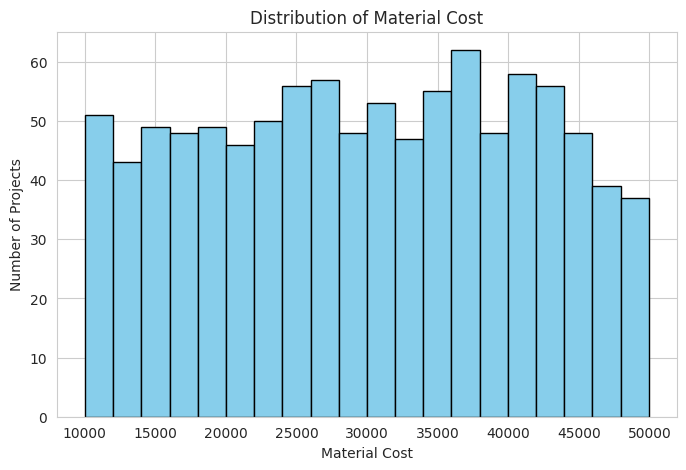

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["Material_Cost"], bins=20, color="skyblue", edgecolor="black")
plt.title("Distribution of Material Cost")
plt.xlabel("Material Cost")
plt.ylabel("Number of Projects")
plt.show()

**Observation:** The histogram shows how frequently different material-cost ranges appear. Look for the ranges with the tallest bars.

### 12.2 Histogram of Total Estimate

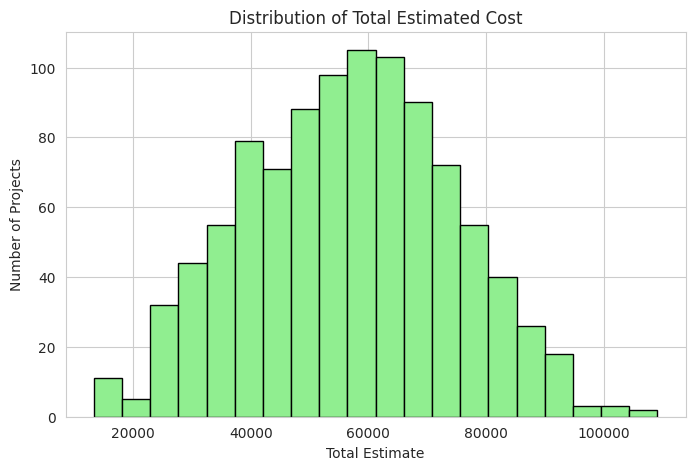

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(df["Total_Estimate"], bins=20, color="lightgreen", edgecolor="black")
plt.title("Distribution of Total Estimated Cost")
plt.xlabel("Total Estimate")
plt.ylabel("Number of Projects")
plt.show()

**Observation:** This plot shows the spread of estimated construction costs and whether most estimates fall in a middle range.

### 12.3 Bar Chart: Average Material Cost and Labor Cost

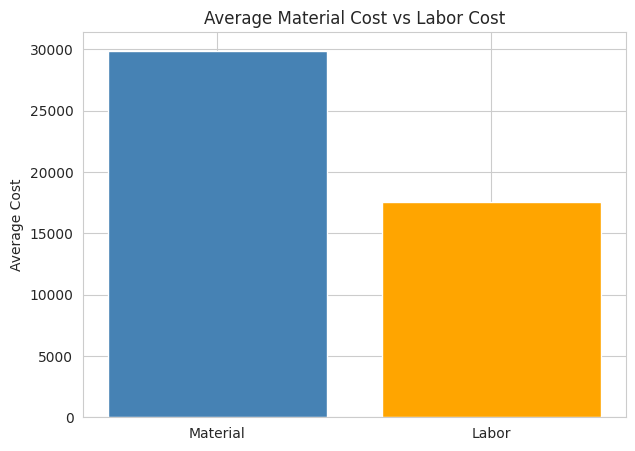

In [16]:
average_costs = df[["Material_Cost", "Labor_Cost"]].mean()
plt.figure(figsize=(7, 5))
plt.bar(["Material", "Labor"], average_costs, color=["steelblue", "orange"])
plt.title("Average Material Cost vs Labor Cost")
plt.ylabel("Average Cost")
plt.show()

**Observation:** Compare the bar heights to identify which cost component is larger on average.

### 12.4 Bar Chart: Average Total Estimate by Profit Rate

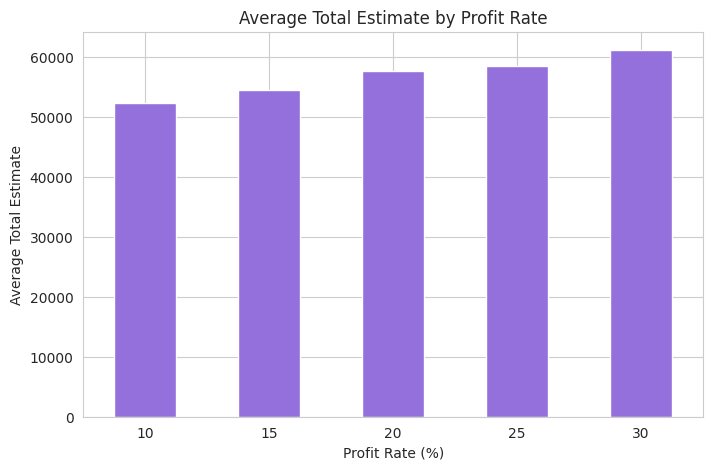

In [17]:
profit_group = df.groupby("Profit_Rate")["Total_Estimate"].mean()
plt.figure(figsize=(8, 5))
profit_group.plot(kind="bar", color="mediumpurple")
plt.title("Average Total Estimate by Profit Rate")
plt.xlabel("Profit Rate (%)")
plt.ylabel("Average Total Estimate")
plt.xticks(rotation=0)
plt.show()

**Observation:** The graph compares average estimates at different profit rates. Other costs can also vary between these groups.

### 12.5 Scatter Plot: Material Cost vs Total Estimate

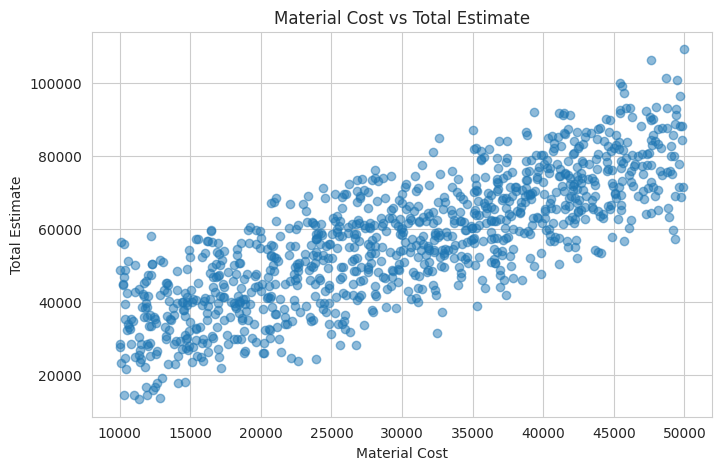

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Material_Cost"], df["Total_Estimate"], alpha=0.5)
plt.title("Material Cost vs Total Estimate")
plt.xlabel("Material Cost")
plt.ylabel("Total Estimate")
plt.show()

**Observation:** An upward pattern indicates that larger material costs are generally associated with larger estimated totals.

### 12.6 Box Plot: Total Estimate

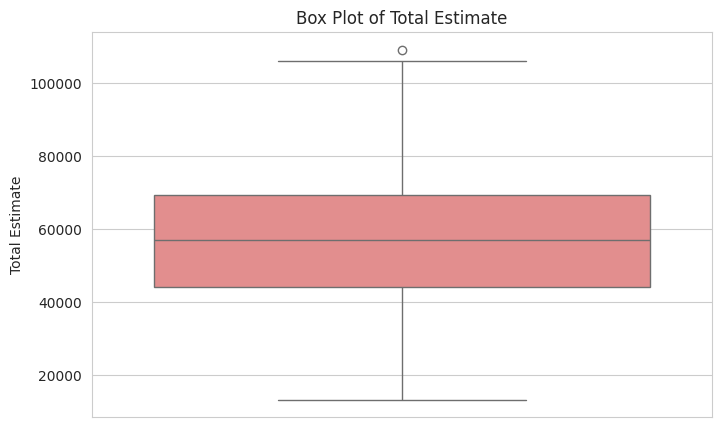

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Total_Estimate"], color="lightcoral")
plt.title("Box Plot of Total Estimate")
plt.ylabel("Total Estimate")
plt.show()

**Observation:** The box represents the middle half of estimates, the line inside is the median, and points beyond the whiskers are possible outliers.

### 12.7 Count Plot: Policy Reasons

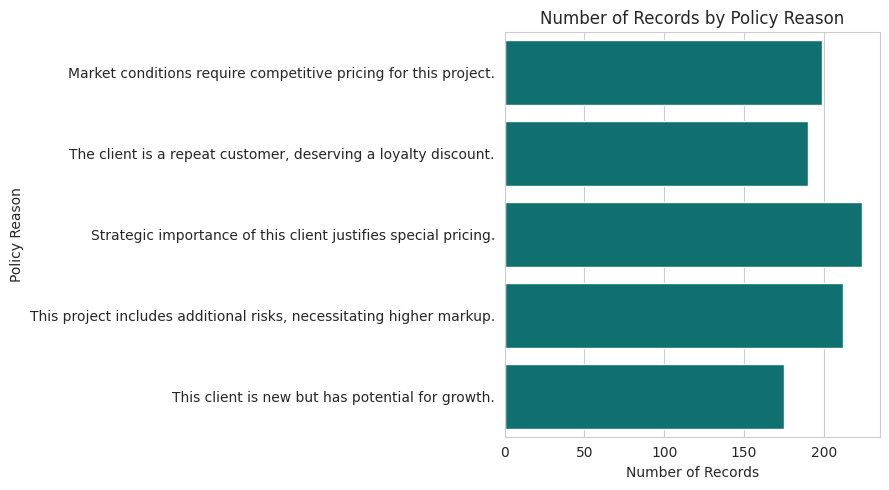

In [20]:
plt.figure(figsize=(9, 5))
sns.countplot(y="Policy_Reason", data=df, color="teal")
plt.title("Number of Records by Policy Reason")
plt.xlabel("Number of Records")
plt.ylabel("Policy Reason")
plt.tight_layout()
plt.show()

**Observation:** This graph compares how often each pricing-policy reason appears in the dataset.

### 12.8 Correlation Heatmap

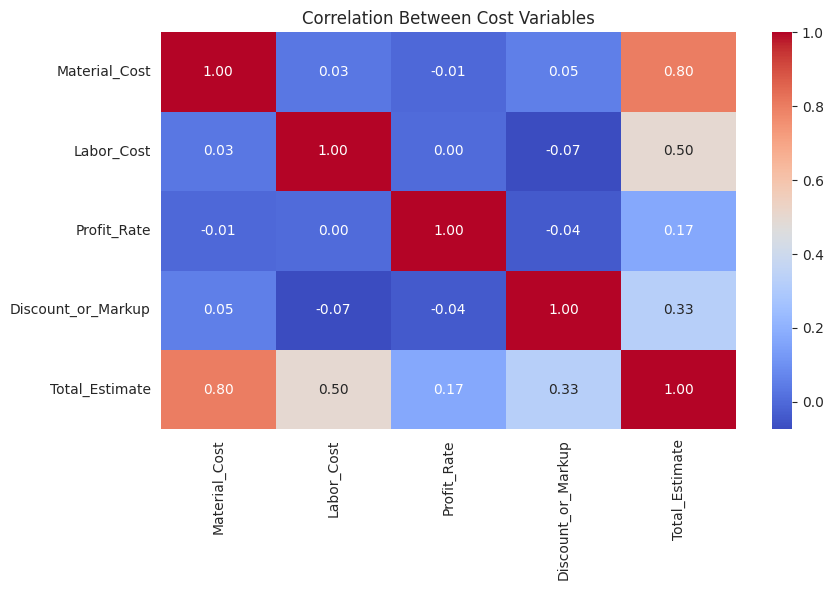

In [21]:
columns = ["Material_Cost", "Labor_Cost", "Profit_Rate",
           "Discount_or_Markup", "Total_Estimate"]
correlation = df[columns].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Cost Variables")
plt.tight_layout()
plt.show()

**Observation:** Values close to +1 show a strong positive linear relationship, near -1 a negative one, and near 0 a weak linear relationship. Total estimate is calculated using the other numerical columns, so correlations are partly expected.

### 12.9 Pair Plot of Cost Variables

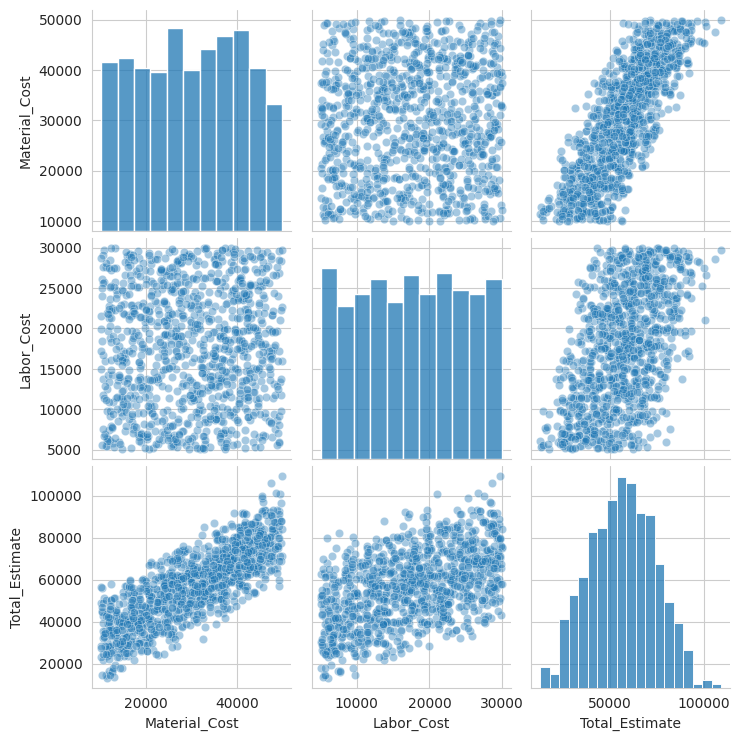

In [22]:
sns.pairplot(df[["Material_Cost", "Labor_Cost", "Total_Estimate"]],
             plot_kws={"alpha": 0.4})
plt.show()

**Observation:** Pair plots display distributions on the diagonal and relationships between each pair of selected variables.

## 13. Discount and Markup Analysis
Positive values of `Discount_or_Markup` represent markups; negative values represent discounts. A zero value means no adjustment.

In [23]:
df["Adjustment_Type"] = np.where(df["Discount_or_Markup"] > 0, "Markup",
                          np.where(df["Discount_or_Markup"] < 0, "Discount", "No Change"))
print("Number of projects in each adjustment type:")
print(df["Adjustment_Type"].value_counts())
print("\nAverage total estimate by adjustment type:")
print(df.groupby("Adjustment_Type")["Total_Estimate"].mean().round(2))

Number of projects in each adjustment type:
Adjustment_Type
Discount    506
Markup      494
Name: count, dtype: int64

Average total estimate by adjustment type:
Adjustment_Type
Discount    51723.67
Markup      61938.29
Name: Total_Estimate, dtype: float64


## 14. Additional Pandas Analysis and Visualizations
The following analyses extend the earlier sections using sorting, ranking, filtering, reshaping, and comparisons.

### 14.1 Lowest Estimated Construction Costs
The ten smallest estimates are identified using ascending sorting.

In [24]:
print("Ten lowest estimated costs:")
display(df.sort_values("Total_Estimate").head(10))

Ten lowest estimated costs:


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference,Adjustment_Type
471,11412,6049,15,-6761,This client is new but has potential for growth.,13319.15,17461,2619.15,13319.15,-0.0,Discount
480,12893,5377,10,-6325,This client is new but has potential for growth.,13772.00,18270,1827.00,13772.00,0.0,Discount
246,11027,5477,25,-6272,"The client is a repeat customer, deserving a l...",14358.00,16504,4126.00,14358.00,0.0,Discount
519,11953,9824,10,-9491,This client is new but has potential for growth.,14463.70,21777,2177.70,14463.70,0.0,Discount
724,10305,5660,10,-2969,"The client is a repeat customer, deserving a l...",14592.50,15965,1596.50,14592.50,0.0,Discount
427,12375,7735,20,-8268,"This project includes additional risks, necess...",15864.00,20110,4022.00,15864.00,0.0,Discount
377,11864,7429,15,-5650,Market conditions require competitive pricing ...,16536.95,19293,2893.95,16536.95,0.0,Discount
479,12502,7764,25,-8702,"This project includes additional risks, necess...",16630.50,20266,5066.50,16630.50,0.0,Discount
910,14160,5721,20,-6228,Strategic importance of this client justifies ...,17629.20,19881,3976.20,17629.20,0.0,Discount
853,12651,9439,25,-9824,Strategic importance of this client justifies ...,17788.50,22090,5522.50,17788.50,0.0,Discount


### 14.2 Ranking Projects by Estimated Cost
Rank 1 indicates the highest estimated cost. A new column stores the rank.

In [25]:
df["Cost_Rank"] = df["Total_Estimate"].rank(ascending=False, method="min").astype(int)
print("Top ten ranked estimates:")
display(df.sort_values("Cost_Rank").head(10))

Top ten ranked estimates:


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference,Adjustment_Type,Cost_Rank
737,49947,29641,30,5701,"The client is a repeat customer, deserving a l...",109165.4,79588,23876.4,109165.4,0.0,Markup,1
22,47605,28582,30,7044,Market conditions require competitive pricing ...,106087.1,76187,22856.1,106087.1,0.0,Markup,2
445,48712,26626,30,3339,This client is new but has potential for growth.,101278.4,75338,22601.4,101278.4,0.0,Markup,3
293,49445,21051,30,9093,Market conditions require competitive pricing ...,100737.8,70496,21148.8,100737.8,0.0,Markup,4
679,45436,27530,30,4988,This client is new but has potential for growth.,99843.8,72966,21889.8,99843.8,0.0,Markup,5
133,45570,25243,30,7039,"This project includes additional risks, necess...",99095.9,70813,21243.9,99095.9,0.0,Markup,6
668,45751,28264,20,8321,Strategic importance of this client justifies ...,97139.0,74015,14803.0,97139.0,0.0,Markup,7
256,49691,28396,20,2562,"The client is a repeat customer, deserving a l...",96266.4,78087,15617.4,96266.4,0.0,Markup,8
517,47973,26601,20,3850,Strategic importance of this client justifies ...,93338.8,74574,14914.8,93338.8,0.0,Markup,9
212,46141,25705,20,6976,Market conditions require competitive pricing ...,93191.2,71846,14369.2,93191.2,0.0,Markup,10


### 14.3 Filtering Estimates Above the Average
Boolean filtering selects records whose estimated cost is above the overall mean.

In [26]:
average_estimate = df["Total_Estimate"].mean()
above_average = df.loc[df["Total_Estimate"] > average_estimate]
print("Overall average:", round(average_estimate, 2))
print("Number above average:", len(above_average))
display(above_average.head())

Overall average: 56769.69
Number above average: 510


,Material_Cost,Labor_Cost,Profit_Rate,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference,Adjustment_Type,Cost_Rank
0,43985,12836,10,1095,Market conditions require competitive pricing ...,63598.10,56821,5682.10,63598.10,0.0,Markup,356
1,45504,17873,15,-6426,Market conditions require competitive pricing ...,66457.55,63377,9506.55,66457.55,0.0,Discount,304
2,33656,8401,25,9862,"The client is a repeat customer, deserving a l...",62433.25,42057,10514.25,62433.25,0.0,Markup,381
3,36509,8523,20,8096,"The client is a repeat customer, deserving a l...",62134.40,45032,9006.40,62134.40,0.0,Markup,390
4,37372,14123,30,-9598,Strategic importance of this client justifies ...,57345.50,51495,15448.50,57345.50,0.0,Discount,495


### 14.4 Filtering High Profit Rates
Records with a profit rate of at least 25 percent are selected.

In [27]:
high_profit = df.loc[df["Profit_Rate"] >= 25]
print("Records with profit rate at least 25%:", len(high_profit))
display(high_profit[["Material_Cost", "Labor_Cost", "Profit_Rate", "Total_Estimate"]].head())

Records with profit rate at least 25%: 379


,Material_Cost,Labor_Cost,Profit_Rate,Total_Estimate
2,33656,8401,25,62433.25
4,37372,14123,30,57345.50
5,27906,28796,25,73426.50
6,26951,21899,25,61506.50
14,21361,9585,25,40656.50


### 14.5 Categorizing Estimates into Cost Levels
Quantile cutoffs divide estimated costs into three similarly sized categories. These are relative labels within this dataset.

In [28]:
df["Cost_Category"] = pd.qcut(df["Total_Estimate"], q=3, labels=["Low", "Medium", "High"])
print("Number of estimates in each category:")
print(df["Cost_Category"].value_counts().sort_index())

Number of estimates in each category:
Cost_Category
Low       334
Medium    332
High      334
Name: count, dtype: int64


### 14.6 Material and Labor Cost Contributions
The percentage share of each cost component is calculated from the base cost.

In [29]:
df["Material_Percent"] = df["Material_Cost"] / df["Base_Cost"] * 100
df["Labor_Percent"] = df["Labor_Cost"] / df["Base_Cost"] * 100
print("Average material share:", round(df["Material_Percent"].mean(), 2), "%")
print("Average labor share:", round(df["Labor_Percent"].mean(), 2), "%")
display(df[["Material_Percent", "Labor_Percent"]].head().round(2))

Average material share: 62.39 %
Average labor share: 37.61 %


,Material_Percent,Labor_Percent
0,77.41,22.59
1,71.80,28.20
2,80.02,19.98
3,81.07,18.93
4,72.57,27.43


### 14.7 Grouping with Multiple Aggregate Functions
The `agg()` function calculates count, mean, median, and standard deviation by profit rate.

In [30]:
summary = df.groupby("Profit_Rate")["Total_Estimate"].agg(["count", "mean", "median", "std"])
display(summary.round(2))

,count,mean,median,std
Profit_Rate,,,,
10,199,52328.32,52246.40,16713.23
15,215,54612.29,54233.10,16620.93
20,207,57742.30,59318.40,17193.30
25,197,58489.70,59955.25,17579.92
30,182,61206.52,61019.10,18139.12


### 14.8 Grouping by Adjustment Type
The mean material, labor, and total estimated costs are compared for discounts and markups.

In [31]:
adjustment_summary = df.groupby("Adjustment_Type")[["Material_Cost", "Labor_Cost", "Total_Estimate"]].mean()
display(adjustment_summary.round(2))

,Material_Cost,Labor_Cost,Total_Estimate
Adjustment_Type,,,
Discount,29297.08,17978.43,51723.67
Markup,30535.28,17144.17,61938.29


### 14.9 Pivot Table Analysis
A pivot table summarizes average total estimates for each profit rate and adjustment type.

In [32]:
pivot = pd.pivot_table(df, values="Total_Estimate", index="Profit_Rate", columns="Adjustment_Type", aggfunc="mean")
print("Average estimated cost by profit rate and adjustment type:")
display(pivot.round(2))

Average estimated cost by profit rate and adjustment type:


Adjustment_Type,Discount,Markup
Profit_Rate,,
10,47378.28,57131.32
15,50088.19,58772.85
20,51665.30,63760.87
25,53317.14,63822.23
30,56046.86,67785.10


### 14.10 Multi-Level Indexing
Two columns are used together as a hierarchical index.

In [33]:
multi = df.set_index(["Profit_Rate", "Adjustment_Type"])
print("First five rows of MultiIndex data:")
display(multi.head())
print("Records with profit rate 10%:")
display(multi.loc[10].head())

First five rows of MultiIndex data:


,,Material_Cost,Labor_Cost,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference,Cost_Rank,Cost_Category,Material_Percent,Labor_Percent
Profit_Rate,Adjustment_Type,,,,,,,,,,,,,
10,Markup,43985,12836,1095,Market conditions require competitive pricing ...,63598.10,56821,5682.10,63598.10,0.0,356,Medium,77.409760,22.590240
15,Discount,45504,17873,-6426,Market conditions require competitive pricing ...,66457.55,63377,9506.55,66457.55,0.0,304,High,71.798918,28.201082
25,Markup,33656,8401,9862,"The client is a repeat customer, deserving a l...",62433.25,42057,10514.25,62433.25,0.0,381,Medium,80.024728,19.975272
20,Markup,36509,8523,8096,"The client is a repeat customer, deserving a l...",62134.40,45032,9006.40,62134.40,0.0,390,Medium,81.073459,18.926541
30,Discount,37372,14123,-9598,Strategic importance of this client justifies ...,57345.50,51495,15448.50,57345.50,0.0,495,Medium,72.574036,27.425964


Records with profit rate 10%:


,Material_Cost,Labor_Cost,Discount_or_Markup,Policy_Reason,Total_Estimate,Base_Cost,Profit_Amount,Calculated_Estimate,Difference,Cost_Rank,Cost_Category,Material_Percent,Labor_Percent
Adjustment_Type,,,,,,,,,,,,,
Markup,43985,12836,1095,Market conditions require competitive pricing ...,63598.1,56821,5682.1,63598.1,0.0,356,Medium,77.409760,22.590240
Discount,20945,25877,-3145,"The client is a repeat customer, deserving a l...",48359.2,46822,4682.2,48359.2,0.0,680,Low,44.733245,55.266755
Markup,37157,20585,4832,Strategic importance of this client justifies ...,68348.2,57742,5774.2,68348.2,0.0,273,High,64.350040,35.649960
Discount,10431,13808,-4970,This client is new but has potential for growth.,21692.9,24239,2423.9,21692.9,0.0,988,Low,43.033954,56.966046
Discount,46223,22701,-3047,"The client is a repeat customer, deserving a l...",72769.4,68924,6892.4,72769.4,0.0,190,High,67.063722,32.936278


### 14.11 Sorting a Multi-Level Index
`sort_index()` arranges records by the hierarchical index.

In [34]:
sorted_multi = multi.sort_index()
print("Sorted MultiIndex data:")
display(sorted_multi.head(10))

Sorted MultiIndex data:


Material_Cost  Labor_Cost  Discount_or_Markup  \
Profit_Rate Adjustment_Type                                                  
10          Discount                 20945       25877               -3145   
            Discount                 10431       13808               -4970   
            Discount                 46223       22701               -3047   
            Discount                 22457       20356               -8204   
            Discount                 47266       13665               -2957   
            Discount                 16236       14854               -8009   
            Discount                 15880       13796               -8944   
            Discount                 24840       15112               -4317   
            Discount                 46702       17663               -1741   
            Discount                 42441       24652               -9240   

                                                                 Policy_Reason  \
Profit_Rate Adjustment_Type                                                      
10          Discount         The client is a repeat customer, deserving a l...   
            Discount          This client is new but has potential for growth.   
            Discount         The client is a repeat customer, deserving a l...   
            Discount          This client is new but has potential for growth.   
            Discount         Strategic importance of this client justifies ...   
            Discount         Market conditions require competitive pricing ...   
            Discount         Market conditions require competitive pricing ...   
            Discount         Strategic importance of this client justifies ...   
            Discount         The client is a repeat customer, deserving a l...   
            Discount         This project includes additional risks, necess...   

                             Total_Estimate  Base_Cost  Profit_Amount  \
Profit_Rate Adjustment_Type                                             
10          Discount                48359.2      46822         4682.2   
            Discount                21692.9      24239         2423.9   
            Discount                72769.4      68924         6892.4   
            Discount                38890.3      42813         4281.3   
            Discount                64067.1      60931         6093.1   
            Discount                26190.0      31090         3109.0   
            Discount                23699.6      29676         2967.6   
            Discount                39630.2      39952         3995.2   
            Discount                69060.5      64365         6436.5   
            Discount                64562.3      67093         6709.3   

                             Calculated_Estimate  Difference  Cost_Rank  \
Profit_Rate Adjustment_Type                                               
10          Discount                     48359.2         0.0        680   
            Discount                     21692.9         0.0        988   
            Discount                     72769.4         0.0        190   
            Discount                     38890.3         0.0        832   
            Discount                     64067.1        -0.0        351   
            Discount                     26190.0         0.0        963   
            Discount                     23699.6         0.0        980   
            Discount                     39630.2         0.0        823   
            Discount                     69060.5         0.0        254   
            Discount                     64562.3         0.0        344   

                            Cost_Category  Material_Percent  Labor_Percent  
Profit_Rate Adjustment_Type                                                 
10          Discount                  Low         44.733245      55.266755  
            Discount                  Low         43.033954      56.966046  
            Discount 

### 14.12 Stack and Unstack
A grouped table is reshaped from wide to long format and back.

In [35]:
grouped_cost = df.groupby(["Profit_Rate", "Adjustment_Type"])["Total_Estimate"].mean()
wide_table = grouped_cost.unstack()
print("Unstacked table:")
display(wide_table.round(2))
print("Stacked table:")
display(wide_table.stack().head(10).round(2))

Unstacked table:


Adjustment_Type,Discount,Markup
Profit_Rate,,
10,47378.28,57131.32
15,50088.19,58772.85
20,51665.30,63760.87
25,53317.14,63822.23
30,56046.86,67785.10


Stacked table:


Profit_Rate  Adjustment_Type
10           Discount           47378.28
             Markup             57131.32
15           Discount           50088.19
             Markup             58772.85
20           Discount           51665.30
             Markup             63760.87
25           Discount           53317.14
             Markup             63822.23
30           Discount           56046.86
             Markup             67785.10
dtype: float64

### 14.13 Bar Chart: Average Cost Components by Profit Rate
This graph compares average material and labor costs at different profit rates.

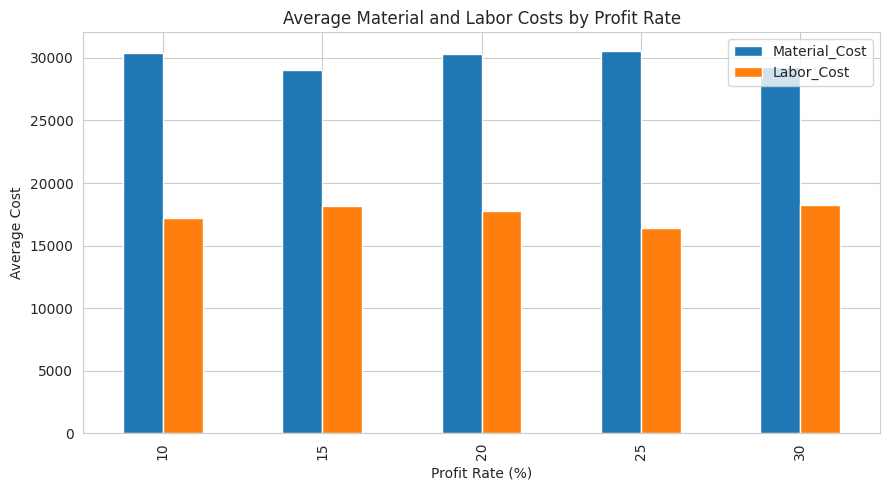

In [36]:
cost_comparison = df.groupby("Profit_Rate")[["Material_Cost", "Labor_Cost"]].mean()
cost_comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Average Material and Labor Costs by Profit Rate")
plt.xlabel("Profit Rate (%)")
plt.ylabel("Average Cost")
plt.legend()
plt.tight_layout()
plt.show()

### 14.14 Box Plot by Profit Rate
A box plot compares the spread and median of total estimated costs across profit rates.

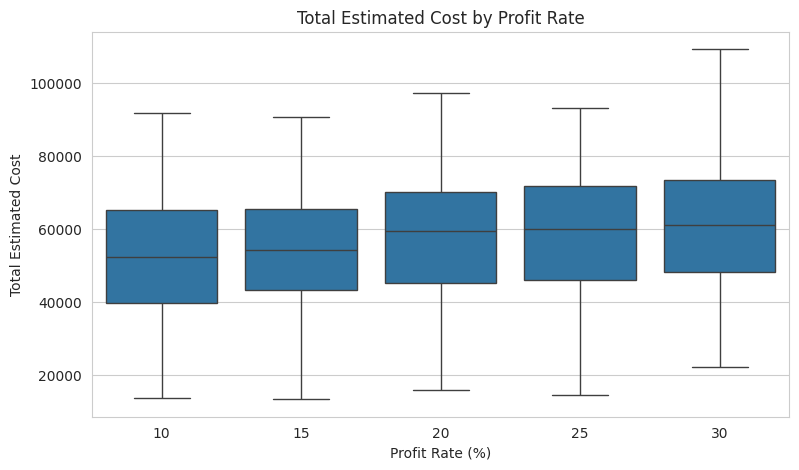

In [37]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Profit_Rate", y="Total_Estimate")
plt.title("Total Estimated Cost by Profit Rate")
plt.xlabel("Profit Rate (%)")
plt.ylabel("Total Estimated Cost")
plt.show()

### 14.15 Violin Plot by Profit Rate
A violin plot shows the distribution of estimated costs for each profit rate.

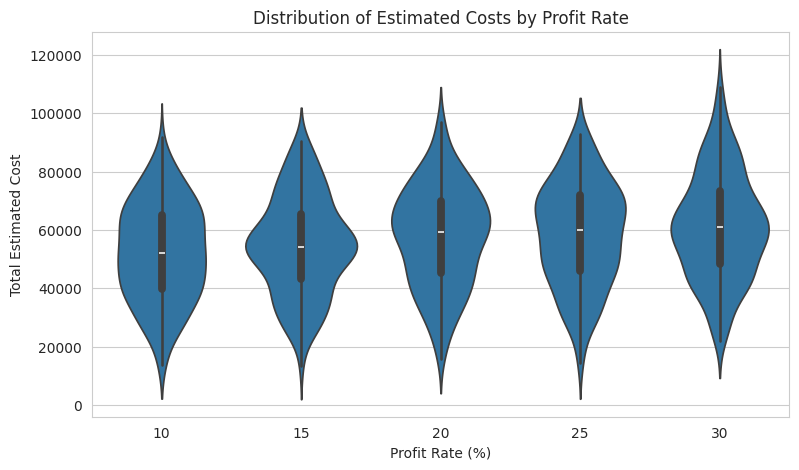

In [38]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="Profit_Rate", y="Total_Estimate")
plt.title("Distribution of Estimated Costs by Profit Rate")
plt.xlabel("Profit Rate (%)")
plt.ylabel("Total Estimated Cost")
plt.show()

### 14.16 Count Plot of Cost Categories
The count plot displays the number of estimates in each relative cost category.

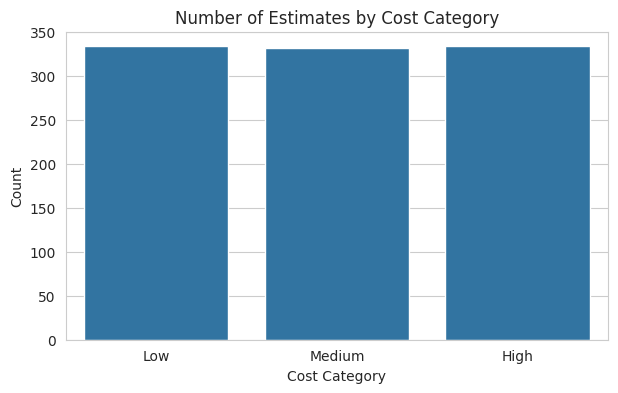

In [39]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Cost_Category", order=["Low", "Medium", "High"])
plt.title("Number of Estimates by Cost Category")
plt.xlabel("Cost Category")
plt.ylabel("Count")
plt.show()

### 14.17 Pair Plot Including Profit Rate
The existing pair plot is retained; this additional plot includes profit rate for comparison.

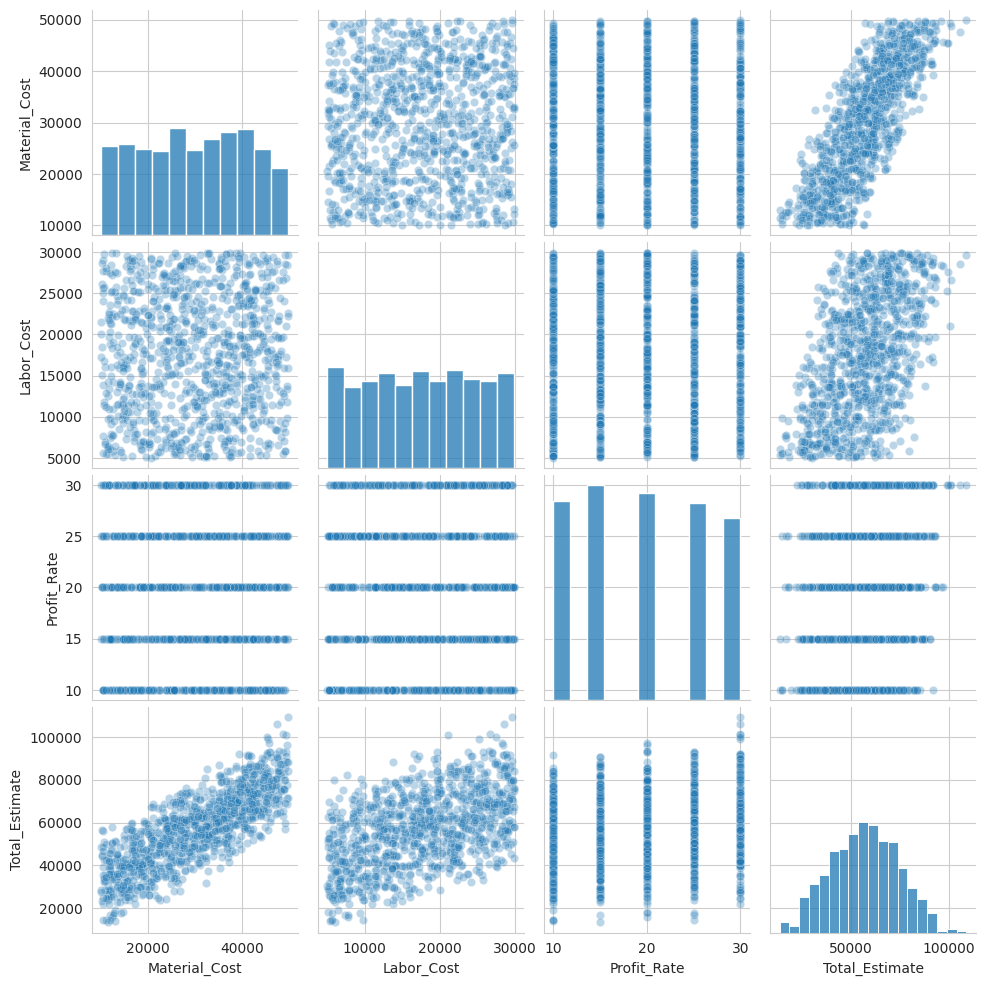

In [40]:
sns.pairplot(df[["Material_Cost", "Labor_Cost", "Profit_Rate", "Total_Estimate"]], plot_kws={"alpha": 0.3})
plt.show()

## 15. Key Findings (Based on the Provided Dataset)

In [41]:
print("Records after cleaning:", len(df))
print("Average material cost:", round(df["Material_Cost"].mean(), 2))
print("Average labor cost:", round(df["Labor_Cost"].mean(), 2))
print("Average final estimate:", round(df["Total_Estimate"].mean(), 2))
print("Minimum final estimate:", df["Total_Estimate"].min())
print("Maximum final estimate:", df["Total_Estimate"].max())
print("Most common policy reason:", df["Policy_Reason"].mode()[0])

Records after cleaning: 1000
Average material cost: 29908.75
Average labor cost: 17566.31
Average final estimate: 56769.69
Minimum final estimate: 13319.15
Maximum final estimate: 109165.4
Most common policy reason: Strategic importance of this client justifies special pricing.


## 16. Conclusion
This project explored 1,000 synthetic construction cost estimates using Pandas, NumPy, Matplotlib, and Seaborn. The analysis examined material and labor costs, profit rates, pricing adjustments, and total estimated costs. Descriptive statistics, grouping, aggregation, sorting, ranking, filtering, pivot tables, multi-level indexing, reshaping, and visualizations were applied to understand patterns in the dataset.

The calculated total estimates were compared with the supplied values. Charts and summary tables help explain how cost components relate to the final estimate. Because the dataset is synthetic and does not include actual expenditure, project dates, or locations, these findings describe the dataset rather than real-world construction performance.

## 17. References
1. **Kaggle — Construction Estimation Data**, Tetsuya Sasaki: https://www.kaggle.com/datasets/sasakitetsuya/construction-estimation-data
2. **Pandas documentation:** https://pandas.pydata.org/docs/
3. **NumPy documentation:** https://numpy.org/doc/
4. **Matplotlib documentation:** https://matplotlib.org/stable/
5. **Seaborn documentation:** https://seaborn.pydata.org/
6. **Google Colab:** https://colab.research.google.com/